# Lab 3: Architectures and their costs

Completed Fashion-MNIST experiment: MLP, CNN, and patch attention. The saved outputs below read the measured results in `results/`. Training was run with the standalone script; optional rerunning is available below.

In [1]:
from pathlib import Path
import json
LAB_DIR = Path.cwd()
if not (LAB_DIR / 'results/results.json').exists():
    raise FileNotFoundError('Open this notebook with lab03 as the working directory.')
rows = json.loads((LAB_DIR / 'results/results.json').read_text())
print('Model       Parameters  Test accuracy  Batch 1 ms  Batch 128 ms')
for r in rows:
    print(f"{r['model']:11s} {r['parameters']:10,d} {100*r['test_accuracy']:12.2f}% {r['latency_b1_ms']:11.4f} {r['latency_b128_ms']:13.4f}")


Model       Parameters  Test accuracy  Batch 1 ms  Batch 128 ms
MLP            235,146        87.97%      0.1019        0.6108
CNN             20,490        89.64%      0.1438       12.1315
Attention       70,794        84.02%      0.3092        4.6009


## Architectures and protocol

MLP: 784 → 256 → 128 → 10. CNN: 1→16 convolution, pool, 16→32 convolution, pool, 1568→10 linear. Attention: 16 patches of 7×7, projection 49→64, two encoder layers (4 heads, feed-forward 128), mean pooling, 64→10.

ToTensor + Normalize((0.2860,), (0.3530,)). Train/validation split 55,000/5,000; test 10,000. Adam 0.001; five epochs; batch 128; seed 42. No positional embeddings. The specified sizes do not satisfy the conflicting 100k–150k parameter target.

Latency uses evaluation/inference mode, 20 warm-ups and medians of 100 runs for batch 1 and 20 for batch 128. Input tensors are already on the device. CPU, four threads.

In [2]:
history = json.loads((LAB_DIR / 'results/history.json').read_text())
for h in history:
    print(f"{h['model']:10s} epoch {h['epoch']}: loss={h['train_loss']:.4f}, validation={100*h['validation_accuracy']:.2f}%")


MLP        epoch 1: loss=0.4919, validation=84.28%
MLP        epoch 2: loss=0.3539, validation=86.20%
MLP        epoch 3: loss=0.3144, validation=86.82%
MLP        epoch 4: loss=0.2902, validation=87.94%
MLP        epoch 5: loss=0.2694, validation=88.48%
CNN        epoch 1: loss=0.5122, validation=86.62%
CNN        epoch 2: loss=0.3356, validation=88.34%
CNN        epoch 3: loss=0.2959, validation=88.70%
CNN        epoch 4: loss=0.2721, validation=89.50%
CNN        epoch 5: loss=0.2542, validation=89.76%
Attention  epoch 1: loss=0.8404, validation=79.30%
Attention  epoch 2: loss=0.5413, validation=82.48%
Attention  epoch 3: loss=0.4828, validation=83.22%
Attention  epoch 4: loss=0.4520, validation=83.00%
Attention  epoch 5: loss=0.4256, validation=84.68%


## Hand-calculated FLOPs

Multiply + add = 2 FLOPs. Biases, pooling, activations, normalization and softmax are omitted from the matrix-operation baseline.

- Linear first layer: 2×784×256 = 401,408; full MLP = 469,504.
- First convolution: 2×3×3×1×16×28×28 = 225,792; second = 1,806,336; head = 31,360; full CNN = 2,063,488.
- Per encoder attention: QKV 393,216 + scores 32,768 + weighted values 32,768 + output 131,072 = 589,824. Feed-forward = 524,288. Two encoders plus patch projection 100,352 and head 1,280 = 2,329,856.

THOP reports MACs. Raw THOP misses attention functional matrix operations; a custom MultiheadAttention hook restores these. Doubling the adjusted count gives a small residual gap from LayerNorm conventions.

In [3]:
for r in rows:
    measured = 2 * r['thop_attention_hook_macs']
    gap = 100 * (measured / r['analytical_flops'] - 1)
    print(f"{r['model']}: analytical={r['analytical_flops']:,}; raw THOP MACs={r['thop_raw_macs']:,.0f}; adjusted x2={measured:,.0f}; gap={gap:.2f}%")


MLP: analytical=469,504; raw THOP MACs=234,752; adjusted x2=469,504; gap=0.00%
CNN: analytical=2,063,488; raw THOP MACs=1,031,744; adjusted x2=2,063,488; gap=0.00%
Attention: analytical=2,329,856; raw THOP MACs=591,488; adjusted x2=2,362,624; gap=1.41%


## Trade-off plots

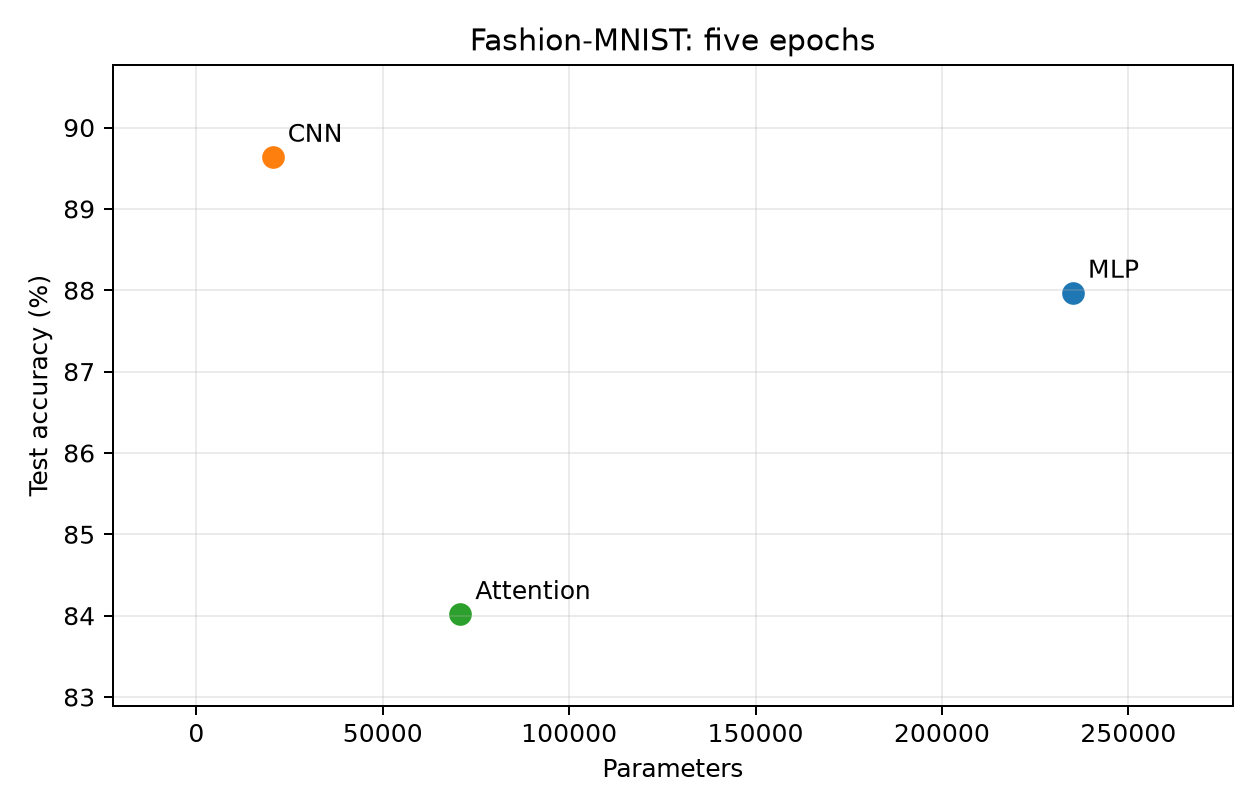

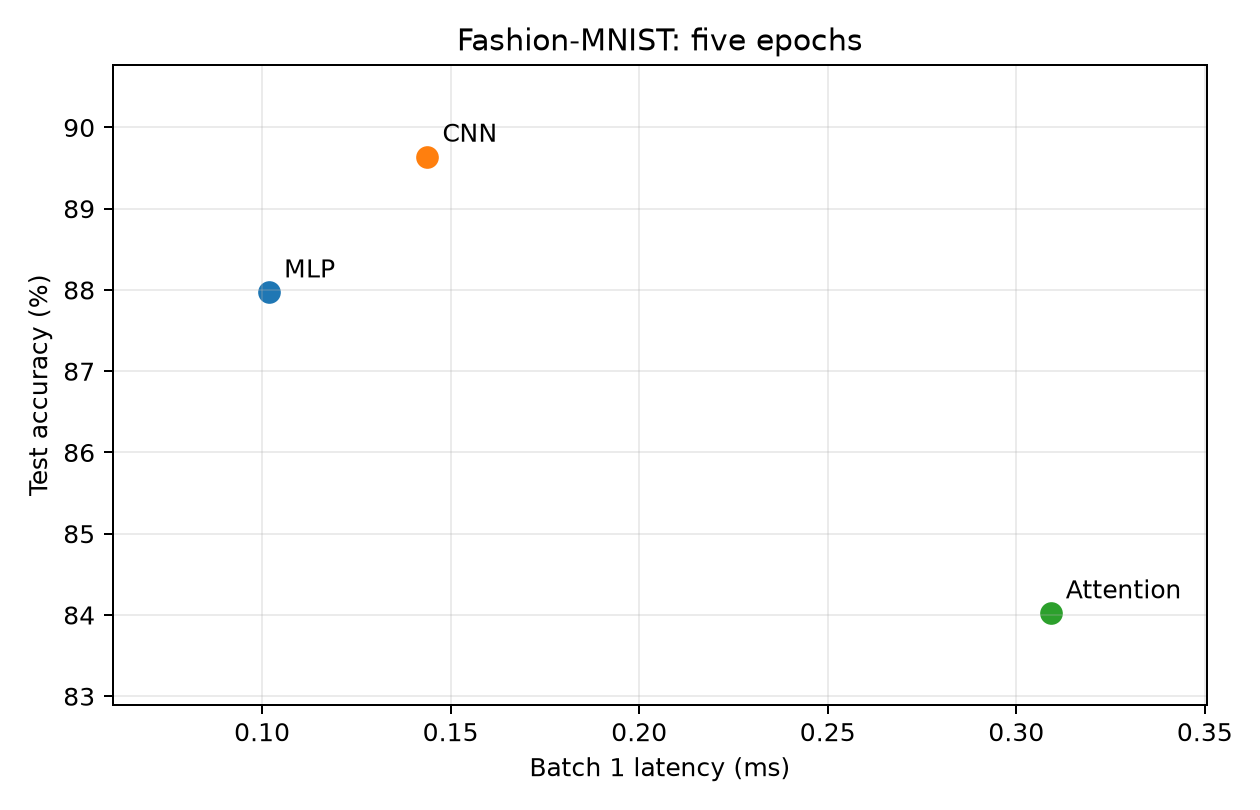

In [4]:
from IPython.display import Image, display
display(Image(filename=str(LAB_DIR / 'results/accuracy_vs_parameters.png')))
display(Image(filename=str(LAB_DIR / 'results/accuracy_vs_latency.png')))


## Conclusion

CNN has the best accuracy/storage trade-off: 89.64% with 20,490 parameters. MLP is fastest on this CPU: 0.102 ms at batch 1 and 0.611 ms at batch 128. Attention reaches 84.02% and offers no observed accuracy/latency advantage over MLP. CNN shares local kernels, MLP streams more weights but benefits from batching, and attention adds token projections and score/normalization traffic. These observations are limited to one seed and five epochs. See report.md for full access-pattern discussion.

In [5]:
RUN_TRAINING = False
if RUN_TRAINING:
    import subprocess, sys
    subprocess.run([sys.executable, str(LAB_DIR / 'lab3.py'), '--data', str(LAB_DIR / 'data'), '--threads', '4'], check=True)
else:
    print('Training skipped: inspecting the saved completed experiment. Set RUN_TRAINING=True to rerun.')


Training skipped: inspecting the saved completed experiment. Set RUN_TRAINING=True to rerun.
